In [157]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

DATA_PATH ='data/ready_to_use'

providers = pd.read_csv(f'{DATA_PATH}/providers_cleaned.csv')

In [158]:
providers.head()

,provider_id,provider_type,specialty_group,years_in_practice,fte_status,panel_size,language_1,language_2,provider_gender,provider_age_band
0,RBPV0001,NP,Primary care,16,Per diem,1717.0,English,NaN,Man,55-64
1,RBPV0002,MD,Primary care,20,Full-time,1705.0,English,NaN,Woman,45-54
2,RBPV0003,MD,Primary care,23,Full-time,1407.0,French,Spanish,Woman,35-44
3,RBPV0004,MD,Primary care,11,Full-time,1475.0,English,NaN,Man,25-34
4,RBPV0005,MD,Primary care,14,Full-time,1452.0,Spanish,NaN,Woman,35-44


In [159]:
providers.info()

<class 'pandas.DataFrame'>
RangeIndex: 180 entries, 0 to 179
Data columns (total 10 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   provider_id        180 non-null    str    
 1   provider_type      180 non-null    str    
 2   specialty_group    180 non-null    str    
 3   years_in_practice  180 non-null    int64  
 4   fte_status         180 non-null    str    
 5   panel_size         70 non-null     float64
 6   language_1         180 non-null    str    
 7   language_2         36 non-null     str    
 8   provider_gender    180 non-null    str    
 9   provider_age_band  180 non-null    str    
dtypes: float64(1), int64(1), str(8)
memory usage: 14.2 KB


In [160]:
providers.describe()

,years_in_practice,panel_size
count,180.000000,70.000000
mean,8.905556,899.342857
std,5.512502,503.678408
min,0.000000,250.000000
25%,5.000000,462.500000
50%,8.000000,725.500000
75%,12.250000,1413.000000
max,28.000000,1876.000000


In [161]:
providers.isnull().sum()

provider_id            0
provider_type          0
specialty_group        0
years_in_practice      0
fte_status             0
panel_size           110
language_1             0
language_2           144
provider_gender        0
provider_age_band      0
dtype: int64

In [162]:
providers.duplicated().sum()

np.int64(0)

In [163]:
providers.shape[0]

180

In [164]:
providers

,provider_id,provider_type,specialty_group,years_in_practice,fte_status,panel_size,language_1,language_2,provider_gender,provider_age_band
0,RBPV0001,NP,Primary care,16,Per diem,1717.0,English,NaN,Man,55-64
1,RBPV0002,MD,Primary care,20,Full-time,1705.0,English,NaN,Woman,45-54
2,RBPV0003,MD,Primary care,23,Full-time,1407.0,French,Spanish,Woman,35-44
3,RBPV0004,MD,Primary care,11,Full-time,1475.0,English,NaN,Man,25-34
4,RBPV0005,MD,Primary care,14,Full-time,1452.0,Spanish,NaN,Woman,35-44
...,...,...,...,...,...,...,...,...,...,...
175,RBPV0176,MD,Pathology,6,Full-time,NaN,French,NaN,Man,55-64
176,RBPV0177,MD,Pathology,7,Full-time,NaN,French,NaN,Man,55-64
177,RBPV0178,MD,Pathology,19,Full-time,NaN,Spanish,NaN,Woman,25-34
178,RBPV0179,MD,Pathology,1,Full-time,NaN,Nepali,NaN,Man,35-44


In [165]:
# the provider type has null values
print(providers[providers['panel_size'].isnull()]['provider_type'].value_counts())

provider_type
MD    49
RN    31
PA    15
NP    11
DO     4
Name: count, dtype: int64


In [166]:
# fill panel size with mean according to provider type   i use median because provider type RN has 31 null can't calculate mean 
providers["panel_size"]=providers["panel_size"].fillna(providers.groupby("provider_type")["panel_size"].transform("median"))
providers["panel_size"]=providers["panel_size"].fillna(providers["panel_size"].median())

In [167]:
# drop the column second langauge it has 140 null
providers=providers.drop(columns=["language_2"])

In [168]:
#check that all null values are filled
providers.isnull().sum()

provider_id          0
provider_type        0
specialty_group      0
years_in_practice    0
fte_status           0
panel_size           0
language_1           0
provider_gender      0
provider_age_band    0
dtype: int64

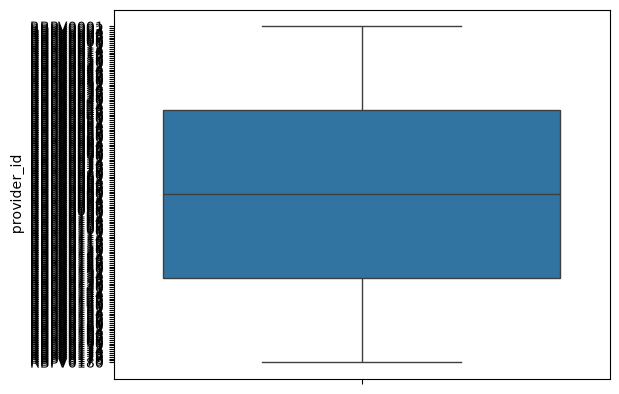

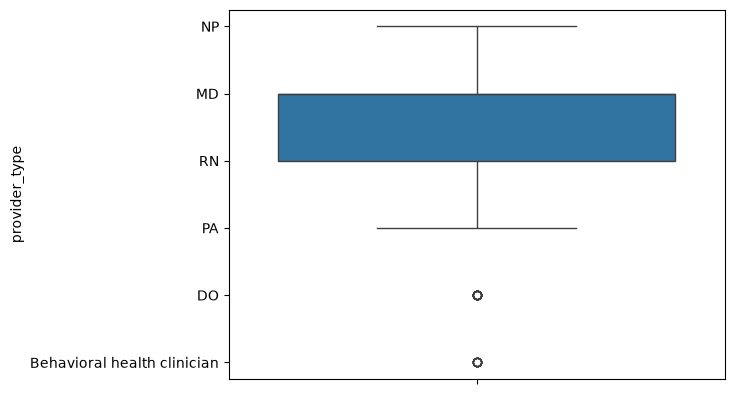

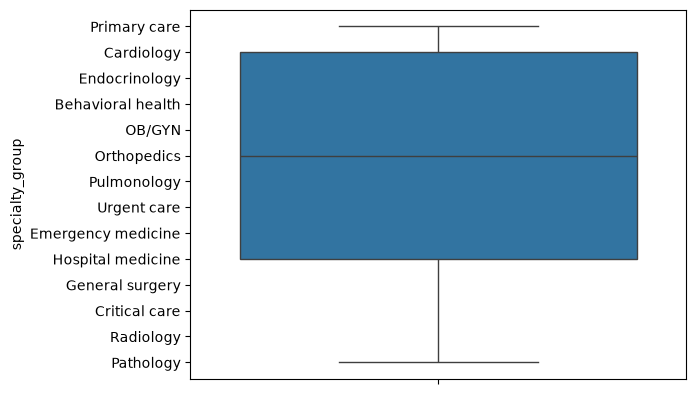

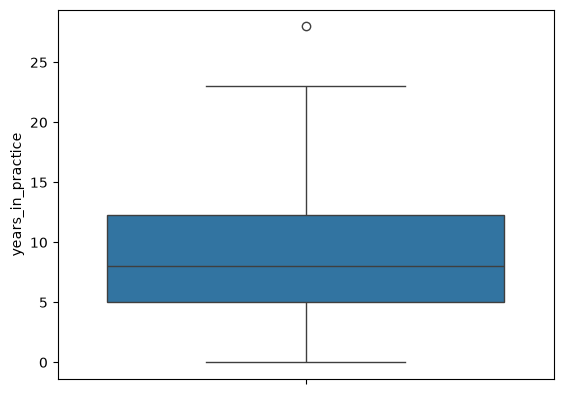

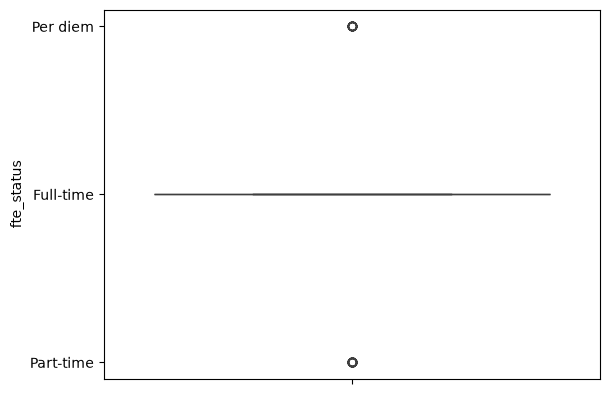

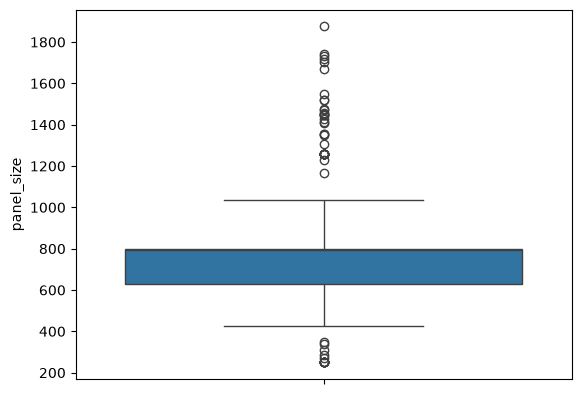

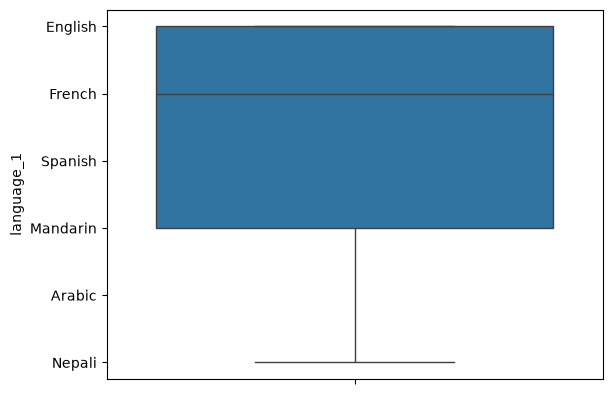

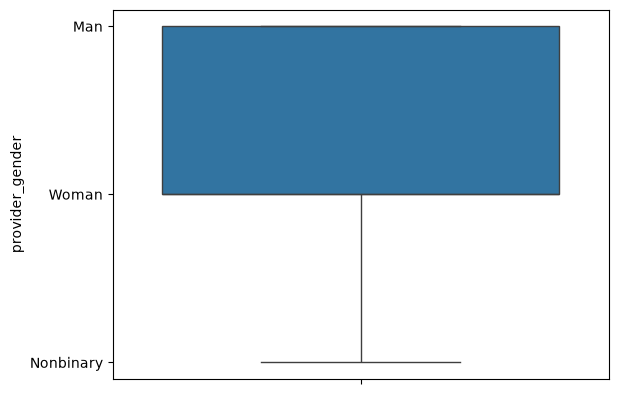

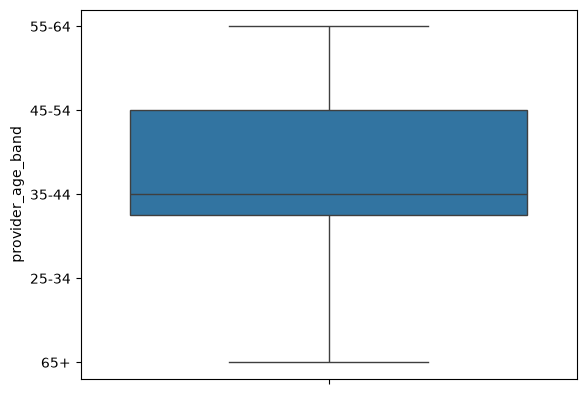

In [169]:
#check for ouliers in panel size ,years in practice
for col in providers:
  sns.boxplot(providers[col])
  plt.show()

In [170]:
# remove outliers in years in practice 
Q1 = providers['years_in_practice'].quantile(0.25)
Q3 = providers['years_in_practice'].quantile(0.75)
IQR = Q3 - Q1

lower_bound = max(0, Q1 - 1.5 * IQR)
upper_bound = Q3 + 1.5 * IQR

print(f"years_in_practice lower bound: {lower_bound}, upper bound: {upper_bound}")


years_in_practice lower bound: 0, upper bound: 23.125


In [171]:
providers= providers[(providers['years_in_practice'] >= lower_bound) & (providers['years_in_practice'] <= upper_bound)]


In [172]:
# remove outliers in panel size
Q1 = providers['panel_size'].quantile(0.25)
Q3 = providers['panel_size'].quantile(0.75)
IQR = Q3 - Q1

lower_bound = max(0, Q1 - 1.5 * IQR)
upper_bound = Q3 + 1.5 * IQR

print(f"panel_size lower bound: {lower_bound}, upper bound: {upper_bound}")
providers= providers[(providers['panel_size'] >= lower_bound) & (providers['panel_size'] <= upper_bound)]


panel_size lower bound: 348.0, upper bound: 1084.0


In [173]:
providers["fte_status"].unique()
providers["fte_status"].str.strip().str.replace("Per diem","Per-diem",regex=True)


5      Part-time
7      Part-time
9      Full-time
13     Full-time
15     Full-time
         ...    
175    Full-time
176    Full-time
177    Full-time
178    Full-time
179    Full-time
Name: fte_status, Length: 128, dtype: str

In [174]:
providers["provider_gender"].unique()

<StringArray>
['Woman', 'Man', 'Nonbinary']
Length: 3, dtype: str

In [175]:
providers["specialty_group"].unique()

<StringArray>
[      'Primary care',         'Cardiology',      'Endocrinology',
  'Behavioral health',             'OB/GYN',        'Orthopedics',
        'Pulmonology',        'Urgent care', 'Emergency medicine',
  'Hospital medicine',    'General surgery',      'Critical care',
          'Radiology',          'Pathology']
Length: 14, dtype: str

In [176]:
providers["language_1"].unique()

<StringArray>
['English', 'Arabic', 'Nepali', 'Mandarin', 'Spanish', 'French']
Length: 6, dtype: str

In [177]:
providers["provider_type"].unique()

providers["provider_type"] = providers["provider_type"].str.strip().str.replace({'Behavioral health clinician':'BHC'},regex=True)

In [178]:
providers["provider_type"].unique()

<StringArray>
['RN', 'DO', 'MD', 'PA', 'NP', 'BHC']
Length: 6, dtype: str

In [179]:
providers["provider_age_band"].unique()

<StringArray>
['45-54', '25-34', '55-64', '35-44', '65+']
Length: 5, dtype: str

In [180]:
# hot encode the categorical columns
from sklearn.preprocessing import LabelEncoder, StandardScaler, OneHotEncoder
cat_cols=['specialty_group','language_1','provider_type','fte_status','provider_gender']
providers = pd.get_dummies(providers,columns=cat_cols,dtype=int)

In [181]:
providers

,provider_id,years_in_practice,panel_size,provider_age_band,specialty_group_Behavioral health,specialty_group_Cardiology,specialty_group_Critical care,specialty_group_Emergency medicine,specialty_group_Endocrinology,specialty_group_General surgery,...,provider_type_MD,provider_type_NP,provider_type_PA,provider_type_RN,fte_status_Full-time,fte_status_Part-time,fte_status_Per diem,provider_gender_Man,provider_gender_Nonbinary,provider_gender_Woman
5,RBPV0006,2,793.0,45-54,0,0,0,0,0,0,...,0,0,0,1,0,1,0,0,0,1
7,RBPV0008,13,793.0,25-34,0,0,0,0,0,0,...,0,0,0,1,0,1,0,1,0,0
9,RBPV0010,16,1035.0,55-64,0,0,0,0,0,0,...,0,0,0,0,1,0,0,0,0,1
13,RBPV0014,3,1020.0,55-64,0,0,0,0,0,0,...,1,0,0,0,1,0,0,1,0,0
15,RBPV0016,13,1000.0,45-54,0,0,0,0,0,0,...,0,0,1,0,1,0,0,1,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
175,RBPV0176,6,793.0,55-64,0,0,0,0,0,0,...,1,0,0,0,1,0,0,1,0,0
176,RBPV0177,7,793.0,55-64,0,0,0,0,0,0,...,1,0,0,0,1,0,0,1,0,0
177,RBPV0178,19,793.0,25-34,0,0,0,0,0,0,...,1,0,0,0,1,0,0,0,0,1
178,RBPV0179,1,793.0,35-44,0,0,0,0,0,0,...,1,0,0,0,1,0,0,1,0,0


In [182]:
#make label encoding for provider_age_band_encoded
le=LabelEncoder()
providers["provider_age_band"]=le.fit_transform(providers["provider_age_band"])

In [183]:
providers["provider_age_band"]

5      2
7      0
9      3
13     3
15     2
      ..
175    3
176    3
177    0
178    1
179    3
Name: provider_age_band, Length: 128, dtype: int64

In [ ]:
#scale the numerical columns
num_cols=['years_in_practice','panel_size']
scaler=StandardScaler()
providers[num_cols]=scaler.fit_transform(providers[num_cols])

In [185]:
providers

,provider_id,years_in_practice,panel_size,provider_age_band,specialty_group_Behavioral health,specialty_group_Cardiology,specialty_group_Critical care,specialty_group_Emergency medicine,specialty_group_Endocrinology,specialty_group_General surgery,...,provider_type_MD,provider_type_NP,provider_type_PA,provider_type_RN,fte_status_Full-time,fte_status_Part-time,fte_status_Per diem,provider_gender_Man,provider_gender_Nonbinary,provider_gender_Woman
5,RBPV0006,-1.367615,0.497878,2,0,0,0,0,0,0,...,0,0,0,1,0,1,0,0,0,1
7,RBPV0008,0.788714,0.497878,0,0,0,0,0,0,0,...,0,0,0,1,0,1,0,1,0,0
9,RBPV0010,1.376804,2.106038,3,0,0,0,0,0,0,...,0,0,0,0,1,0,0,0,0,1
13,RBPV0014,-1.171585,2.006358,3,0,0,0,0,0,0,...,1,0,0,0,1,0,0,1,0,0
15,RBPV0016,0.788714,1.873452,2,0,0,0,0,0,0,...,0,0,1,0,1,0,0,1,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
175,RBPV0176,-0.583495,0.497878,3,0,0,0,0,0,0,...,1,0,0,0,1,0,0,1,0,0
176,RBPV0177,-0.387465,0.497878,3,0,0,0,0,0,0,...,1,0,0,0,1,0,0,1,0,0
177,RBPV0178,1.964893,0.497878,0,0,0,0,0,0,0,...,1,0,0,0,1,0,0,0,0,1
178,RBPV0179,-1.563645,0.497878,1,0,0,0,0,0,0,...,1,0,0,0,1,0,0,1,0,0
